### create a DataFrame:

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 240

hours = np.round(rng.uniform(0.5, 10, n), 1)
attendance = rng.integers(50, 101, n)
sleep = np.round(rng.uniform(4, 9, n), 1)
previous = rng.integers(30, 96, n)
stress = rng.integers(1, 11, n)
week = rng.integers(1, 13, n)

subject = rng.choice(
    ["Math", "Physics", "English"], n
)

study_method = rng.choice(
    ["Solo", "Group", "Online"], n
)

method_effect = np.select(
    [study_method == "Group", study_method == "Online"],
    [3, 1],
    default=0
)

score = (
    5
    + 2.5 * hours
    + 0.16 * attendance
    + 0.50 * previous
    + 1.0 * sleep
    - 1.8 * stress
    + 0.35 * week
    + method_effect
    + rng.normal(0, 7, n)
)

score = np.clip(np.rint(score), 0, 100).astype(int)

df = pd.DataFrame({
    "Student_ID": np.arange(1, n + 1),
    "Hours_Studied": hours,
    "Attendance": attendance,
    "Sleep_Hours": sleep,
    "Previous_Score": previous,
    "Stress_Level": stress,
    "Subject": subject,
    "Study_Method": study_method,
    "Week": week,
    "Exam_Score": score
})

df["Result"] = np.where(
    df["Exam_Score"] >= 60,
    "Pass",
    "Fail"
)

df.head()

,Student_ID,Hours_Studied,Attendance,Sleep_Hours,Previous_Score,Stress_Level,Subject,Study_Method,Week,Exam_Score,Result
0,1,7.9,64,8.7,88,8,Physics,Online,12,72,Pass
1,2,4.7,92,4.6,61,6,Physics,Solo,1,50,Fail
2,3,8.7,62,4.6,94,10,English,Group,1,91,Pass
3,4,7.1,90,4.4,80,5,Physics,Online,10,90,Pass
4,5,1.4,73,7.3,72,2,Physics,Online,5,60,Pass


### Visualize ``Hours_Studied`` against ``Exam_Score`` using the first 15 students, in DataFrame order.

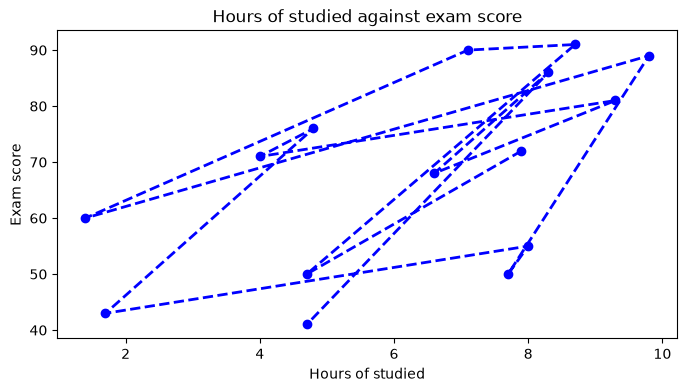

In [51]:
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(df["Hours_Studied"].head(15),df["Exam_Score"].head(15),color="blue",marker="o",linestyle="--", linewidth=2)
ax.set_title("Hours of studied against exam score")
ax.set_xlabel("Hours of studied")
ax.set_ylabel("Exam score")
plt.show()

### Investigate the relationship between Hours_Studied and Exam_Score for all students.

- Function: sns.scatterplot()

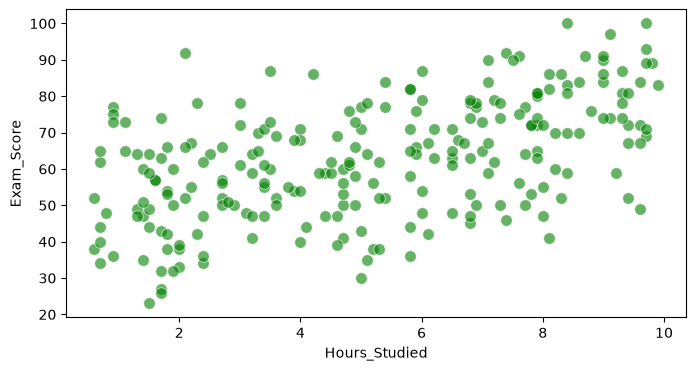

In [52]:
fig, ax = plt.subplots(figsize=(8,4))
sns.scatterplot(df,x="Hours_Studied",y="Exam_Score",color="green",s=70,alpha=0.6,ax=ax)
plt.show()

### Analyze the distribution of Exam_Score.

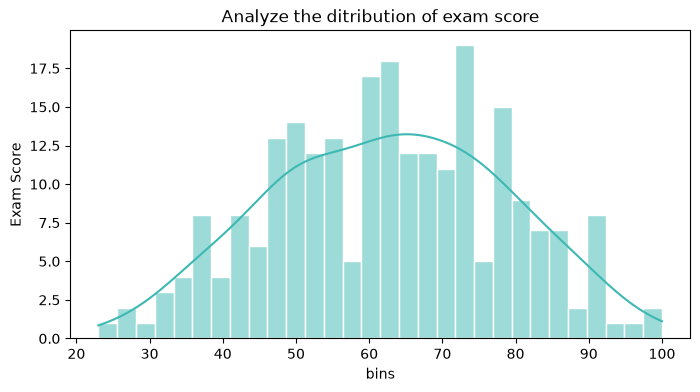

In [53]:
fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(df,x="Exam_Score",bins=30,kde=True,color="#3DB8B3",ax=ax,edgecolor="white")
ax.set_title("Analyze the ditribution of exam score")
ax.set_ylabel("Exam Score")
ax.set_xlabel("bins")

plt.show()

### Compare the number of students using Solo, Group, and Online study methods.

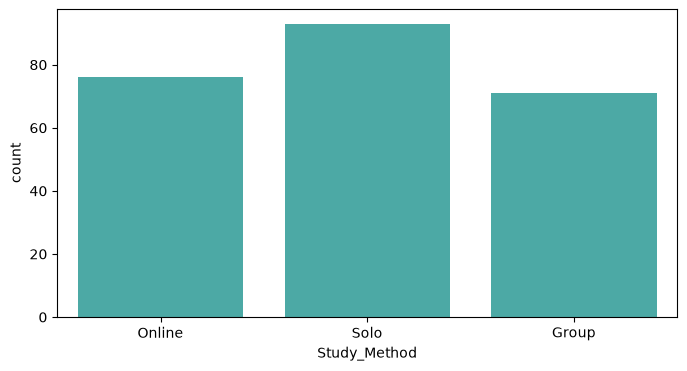

In [54]:
fig, axes= plt.subplots(figsize=(8,4))
sns.countplot(data=df,x="Study_Method",order=['Online','Solo','Group'],color="#3DB8B3")
ax.set_title("Compare the number of studnents using Solo, Group, and Online study methods.")
ax.set_ylabel("Number of students")
ax.set_xlabel("Study method")
plt.show()

### Compare Exam_Score distributions across the three subjects.

In [55]:
df['Subject'].unique()

array(['Physics', 'English', 'Math'], dtype=object)

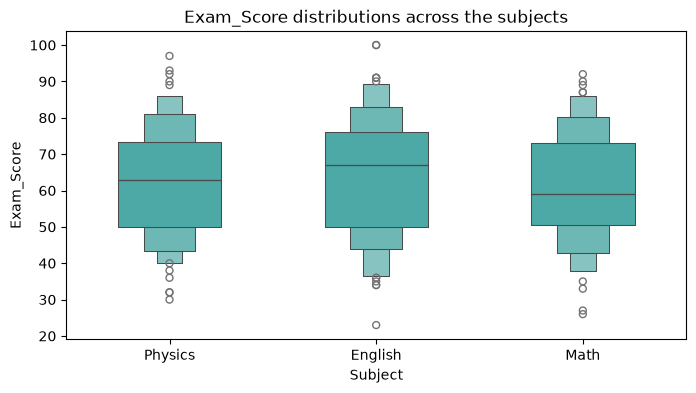

In [64]:
fig, ax= plt.subplots(figsize=(8,4))
sns.boxenplot(df,x="Subject",y="Exam_Score",color="#3DB8B3",ax=ax,width=0.5)
ax.set_title("Exam_Score distributions across the subjects")
plt.show()

### Compare the average exam score for each study method.

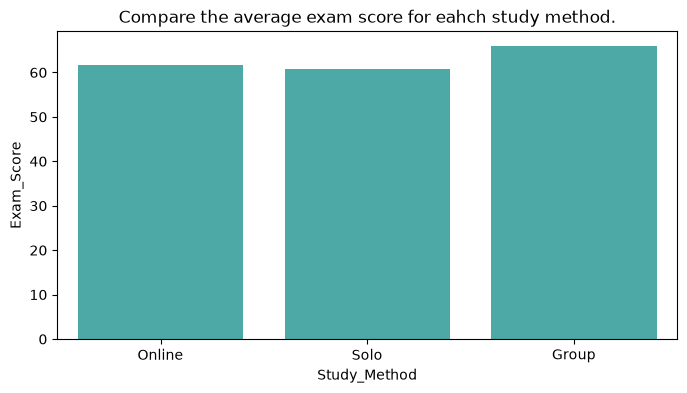

In [78]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(df,x="Study_Method",y="Exam_Score",estimator="mean",errorbar=None,color="#3DB8B3")
ax.set_title("Compare the average exam score for eahch study method.")
plt.show()

### Compare study hours with scores, using colors for Subject and marker shapes for Result.

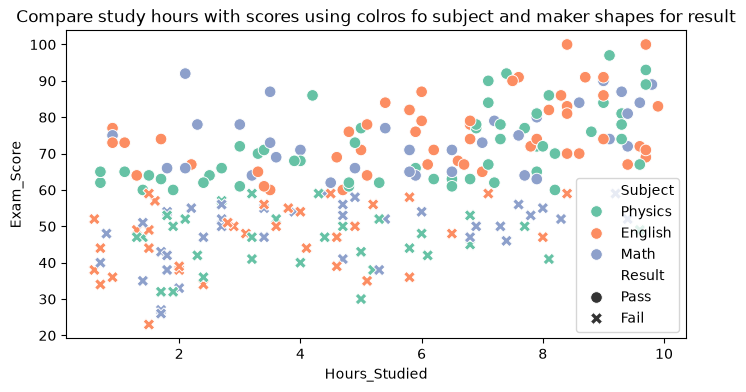

In [92]:
fig, axes = plt.subplots(figsize=(8,4))
sns.scatterplot(df,x="Hours_Studied",y="Exam_Score",hue="Subject",style="Result",palette="Set2",s=70)
axes.set_title("Compare study hours with scores using colros fo subject and maker shapes for result")
plt.show()

### Plot the average Exam_Score for each Week, with a separate line for every subject.

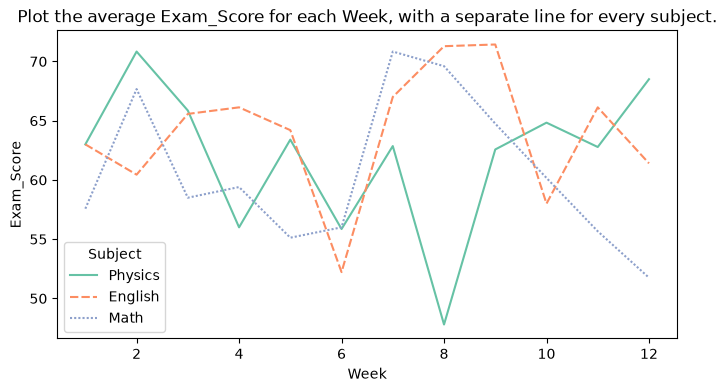

In [111]:
fig, ax = plt.subplots(figsize=(8,4))
sns.lineplot(df,x="Week",y="Exam_Score",hue="Subject",color="#3EAEB1",palette="Set2",estimator="mean",errorbar=None,style="Subject")
ax.set_title("Plot the average Exam_Score for each Week, with a separate line for every subject.")
plt.show()

### Compare the score distributions of Pass and Fail students.

In [ ]:
fig, axes = plt.subplots(figsize=(8,4))
sns.violinplot()

In [93]:
df.columns

Index(['Student_ID', 'Hours_Studied', 'Attendance', 'Sleep_Hours',
       'Previous_Score', 'Stress_Level', 'Subject', 'Study_Method', 'Week',
       'Exam_Score', 'Result'],
      dtype='object')